# Titanic: análisis exploratorio y modelos

Este notebook acompaña a `src/train.py`. Primero explora los datos (¿qué tipo de pasajero
tenía más probabilidad de sobrevivir?), luego explica las variables que se crearon y
termina comparando los tres modelos con validación cruzada.

Los datos no están en el repositorio: descárgalos de la
[competencia](https://www.kaggle.com/competitions/titanic/data) y colócalos en `data/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..") / "src"))
import train as T  # reutiliza el feature engineering del script

# Paleta de referencia: azul y naranja (slots 1 y 2 de la paleta categórica)
BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

raw = pd.read_csv("../data/train.csv")
raw_test = pd.read_csv("../data/test.csv")
print(raw.shape, raw_test.shape)
raw.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Valores faltantes

`Cabin` tiene un 77 % de nulos, así que no sirve directa. `Age` falta en 177 pasajeros
y hay que imputarla.

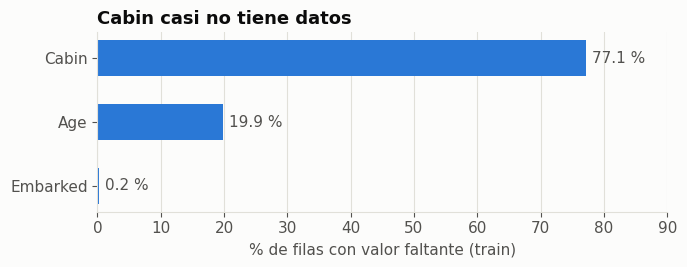

In [2]:
miss = (raw.isna().mean() * 100)
miss = miss[miss > 0].sort_values()

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(miss.index, miss.values, color=BLUE, height=0.55)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
for y, v in enumerate(miss.values):
    ax.text(v + 1, y, f"{v:.1f} %", va="center", color=INK2)
ax.set_xlim(0, 90)
ax.set_xlabel("% de filas con valor faltante (train)")
ax.set_title("Cabin casi no tiene datos")
plt.tight_layout(); plt.show()

## 2. Supervivencia por sexo y clase

Las dos señales más fuertes. En la 1ª y 2ª clase casi todas las mujeres sobreviven,
y en 3ª clase la tasa de las mujeres cae a la mitad. Los hombres tienen tasas bajas
en cualquier clase.

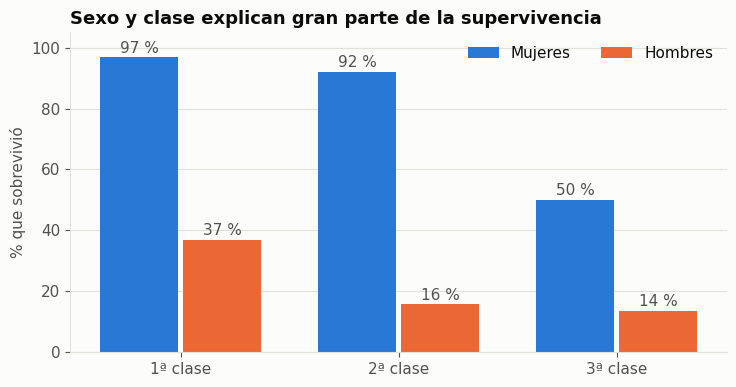

In [3]:
rate = raw.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean") * 100

x = np.arange(3); w = 0.36
fig, ax = plt.subplots(figsize=(7.5, 4))
b1 = ax.bar(x - w/2 - 0.01, rate["female"], w, color=BLUE, label="Mujeres")
b2 = ax.bar(x + w/2 + 0.01, rate["male"], w, color=ORANGE, label="Hombres")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.0f} %",
                ha="center", color=INK2)
ax.set_xticks(x, ["1ª clase", "2ª clase", "3ª clase"])
ax.set_ylim(0, 105); ax.set_ylabel("% que sobrevivió")
ax.set_title("Sexo y clase explican gran parte de la supervivencia")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout(); plt.show()

## 3. Supervivencia por edad

Los menores de 5 años sobreviven mucho más y los mayores de 60 bastante menos; el resto
de edades se parece. Por eso `IsChild` y el título (`Master`) son señales plausibles, aunque en la prueba final
no mejoraron el puntaje.

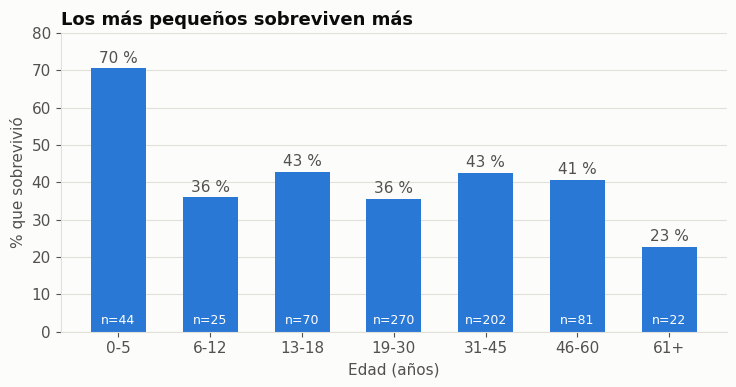

In [4]:
bins = [0, 5, 12, 18, 30, 45, 60, 80]
labels = ["0-5", "6-12", "13-18", "19-30", "31-45", "46-60", "61+"]
age = raw.dropna(subset=["Age"]).copy()
age["grupo"] = pd.cut(age["Age"], bins=bins, labels=labels, include_lowest=True)
g = age.groupby("grupo", observed=True)["Survived"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(g.index.astype(str), g["mean"] * 100, color=BLUE, width=0.6)
for b, n in zip(bars, g["size"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, f"{b.get_height():.0f} %",
            ha="center", color=INK2)
    ax.text(b.get_x() + b.get_width()/2, 2, f"n={n}", ha="center", color="white", fontsize=9)
ax.set_ylim(0, 80); ax.set_xlabel("Edad (años)"); ax.set_ylabel("% que sobrevivió")
ax.set_title("Los más pequeños sobreviven más")
plt.tight_layout(); plt.show()

## 4. Variables que se crearon

`T.add_features` y `T.fill_missing` son las mismas funciones que usa `train.py`:

- **Title**: extraído del nombre (Mr, Mrs, Miss, Master, Rare).
- **FamilySize** e **IsAlone**.
- **Deck** y **HasCabin**, a partir de `Cabin`.
- Imputación calculada **solo con train**: `Age` por mediana del título, `Fare` por
  mediana de la clase y `Embarked` por la moda.

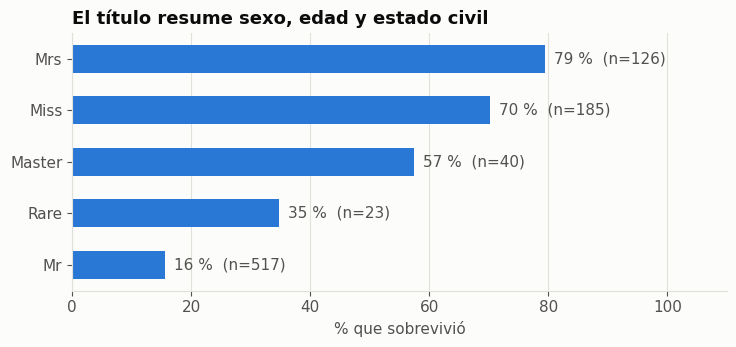

In [5]:
train = T.add_features(raw)
test = T.add_features(raw_test)
train, test = T.fill_missing(train, test)

by_title = train.groupby("Title")["Survived"].agg(["mean", "size"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(by_title.index, by_title["mean"] * 100, color=BLUE, height=0.55)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
for b, n in zip(bars, by_title["size"]):
    ax.text(b.get_width() + 1.5, b.get_y() + b.get_height()/2,
            f"{b.get_width():.0f} %  (n={n})", va="center", color=INK2)
ax.set_xlim(0, 110); ax.set_xlabel("% que sobrevivió")
ax.set_title("El título resume sexo, edad y estado civil")
plt.tight_layout(); plt.show()

## 5. Comparación de modelos

Validación cruzada estratificada de 5 folds, con el mismo `preprocessor` de `train.py`.
La barra de error es una desviación estándar entre folds.

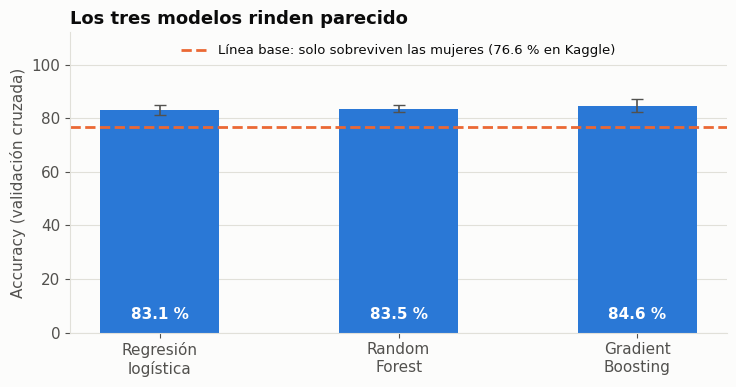

In [6]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X, y = train[T.NUMERIC + T.CATEGORICAL], train["Survived"]
models = {
    "Regresión\nlogística": LogisticRegression(max_iter=1000),
    "Random\nForest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=42),
    "Gradient\nBoosting": GradientBoostingClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res = {n: cross_val_score(make_pipeline(T.preprocessor(), m), X, y, cv=cv, scoring="accuracy")
       for n, m in models.items()}

means = [r.mean() * 100 for r in res.values()]
stds = [r.std() * 100 for r in res.values()]
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(list(res), means, yerr=stds, color=BLUE, width=0.5,
              error_kw={"ecolor": INK2, "capsize": 4, "lw": 1.2})
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, 5, f"{m:.1f} %", ha="center", color="white", fontweight="bold")
ax.axhline(76.6, color=ORANGE, lw=2, ls="--", label="Línea base: solo sobreviven las mujeres (76.6 % en Kaggle)")
ax.set_ylim(0, 112); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel("Accuracy (validación cruzada)")
ax.set_title("Los tres modelos rinden parecido")
ax.legend(loc="upper center", fontsize=9.5)
plt.tight_layout(); plt.show()

## Conclusiones

- Sexo y clase concentran casi toda la señal; el resto de variables aporta poco encima.
- Los tres modelos empatan dentro del ruido (±2 puntos). Gradient Boosting ganó por poco
  en CV, pero esa diferencia no es una victoria clara.
- La CV (84.6 %) es más optimista que el leaderboard público (**77.99 %**): train tiene
  solo 891 filas y el test, 418, donde cada pasajero vale 0.24 puntos.